# Transfer Learning

El transfer learning es una técnica de IA y ML en la que se reutiliza un modelo ya entrenado en una tarea para resolver otra tarea nueva pero relacionada. En lugar de crear y entrenar una red neuronal desde cero, se aprovecha el conocimiento que el modelo original ya acumuló y se adapta a la nueva necesidad.

En este caso, vamos a usar redes neuronales preentrenadas especializadas en el reconocimiento de imágenes.

In [1]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, applications, callbacks
from matplotlib import pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

## Procesado de datos

Cargamos los datos y añadimos una nueva dimensión (el canal). En este caso normalizaremos los datos al crear el modelo, ya que según el modelo preentrenado usa un preprocesado distinto.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train[..., None]
x_test = x_test[..., None]

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Funciones auxiliares

Creamos una función para crear el modelo. Recibimos como parámetro el modelo base ya entrenado. Aumentamos la resolución de entrada ya que sino obtendremos errores ya que la imagen se queda sin píxeles. Añadimos al final del modelo una capa densa para poder clasificar la entrada a una de las 10 clases.

In [3]:
def crear_modelo(base, nombre, preprocess_fn=None):
    entrada = layers.Input(shape=(28, 28, 1))
    x = layers.Resizing(32, 32)(entrada)
    x = layers.Concatenate()([x, x, x])

    if preprocess_fn is not None:
        x = preprocess_fn(x)

    base.trainable = False

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    salida = layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(entrada, salida, name=nombre)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model

def entrenar_evaluar(model, x_tr, y_tr, x_te, y_te, epochs=50):
    calls = [
        callbacks.EarlyStopping(monitor="val_loss", patience=5),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.7, patience=4),
    ]

    t_ini = time.time() # calculamos el tiempo exacto del entrenamiento
    h = model.fit(x_tr, y_tr, epochs=epochs, batch_size=512, validation_split=0.15, callbacks=calls)
    t_total = time.time() - t_ini

    prob_tr = model.predict(x_tr, batch_size=512) # obtenemos las salidas del modelo (una probabilidad)
    prob_te = model.predict(x_te, batch_size=512)
    pred_tr = np.argmax(prob_tr, axis=1) # la predicccion es la salida con mayor probabilidad
    pred_te = np.argmax(prob_te, axis=1)

    acc_tr = accuracy_score(y_tr, pred_tr) # calculamos el accuracy
    acc_te = accuracy_score(y_te, pred_te)

    num_err_tr = int(np.sum(pred_tr.ravel() != y_tr))
    num_err_te = int(np.sum(pred_te.ravel() != y_te))

    prec_te = precision_score(y_te, pred_te, average="macro")
    rec_te = recall_score(y_te, pred_te, average="macro")
    f1_te = f1_score(y_te, pred_te, average="macro")
    auc_te = roc_auc_score(y_te, prob_te, multi_class="ovr")

    cm_tr = confusion_matrix(y_tr, pred_tr) # creamos las matrices de confusion
    cm_te = confusion_matrix(y_te, pred_te)

    metricas = {
        "modelo": model.name,
        "tiempo_entrenamiento(s)": round(t_total, 2),
        "train_accuracy": round(acc_tr, 4),
        "test_accuracy": round(acc_te, 4),
        "errores_train": f"{num_err_tr}/{len(y_tr)}",
        "errores_test": f"{num_err_te}/{len(y_te)}",
        "precision": round(prec_te, 4),
        "recall": round(rec_te, 4),
        "f1_score": round(f1_te, 4),
        "auc_roc": round(auc_te, 4),
    }

    return metricas, model, cm_tr, cm_te, pred_te, h

def resumen(cm_tr, cm_te, h):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    clases = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"  ]

    axes[0, 0].set_title("train cofusion matrix")
    disp_tr = ConfusionMatrixDisplay(cm_tr, display_labels=clases)
    disp_tr.plot(ax=axes[0, 0])

    axes[0, 1].set_title("test confusion matrix")
    disp_te = ConfusionMatrixDisplay(cm_te, display_labels=clases)
    disp_te.plot(ax=axes[0, 1])

    axes[1, 0].plot(h.history["loss"], label="loss", color="b")
    axes[1, 0].plot(h.history["val_loss"], label="validation_loss", color="orange")
    axes[1, 0].set_title("loss curves")
    axes[1, 0].set_xlabel("epochs")
    axes[1, 0].set_ylabel("loss")
    axes[1, 0].legend()
    axes[1, 0].grid(True)

    axes[1, 1].plot(h.history["accuracy"], label="train_accuracy", color="green")
    axes[1, 1].plot(h.history["val_accuracy"], label="validation_accuracy", color="yellow")
    axes[1, 1].set_title("accuracy curves")
    axes[1, 1].set_xlabel("epochs")
    axes[1, 1].set_ylabel("accuracy")
    axes[1, 1].legend()
    axes[1, 1].grid(True)

    plt.tight_layout()
    plt.show()

In [4]:
metricas = pd.DataFrame()

## Desarrollo de modelos
Para cada experimento dejaremos fijos de optimizador (Adam), tamaño de lote (512) y tasa de aprendizaje (0.003). Además hemos incluido un conjunto de validación para ir comprobando como avanza el entrenamiento. Usaremos un 15% del conjunto de entrenamiento como conjunto de validación. También hemos incluido un scheduler para el learning rate y early stopping para evitar el overfitting.

### Experimento 0
Para este experimento usaremos la red VGG16, formada por 16 capas (13 de convolución y 3 fully connected). Usa kernels 3x3, max pooling y función de activación ReLU.

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 126ms/step - accuracy: 0.7616 - loss: 1.5520 - val_accuracy: 0.9127 - val_loss: 0.2749 - learning_rate: 0.0030
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.8936 - loss: 0.3371 - val_accuracy: 0.9331 - val_loss: 0.2097 - learning_rate: 0.0030
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9107 - loss: 0.2728 - val_accuracy: 0.9382 - val_loss: 0.1961 - learning_rate: 0.0030
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9252 - loss: 0.2342 - val_accuracy: 0.9459 - val_loss: 0.1687 - learning_rate: 0.0030
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9315 - loss: 0.2110 - val_accuracy: 0.9492 - val_loss: 0.1621 - learning_rate: 0.0030
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9365 - loss: 0.1932 - val_accuracy: 0.9508 - val_loss: 0.1516 - learning_rate: 0.0030
Epoch 7/50
100/100 ━━━━━━━━━━

,modelo,tiempo_entrenamiento(s),train_accuracy,test_accuracy,errores_train,errores_test,precision,recall,f1_score,auc_roc
0,VGG16,210.0,0.9805,0.9616,1170/60000,384/10000,0.961,0.961,0.9609,0.9986


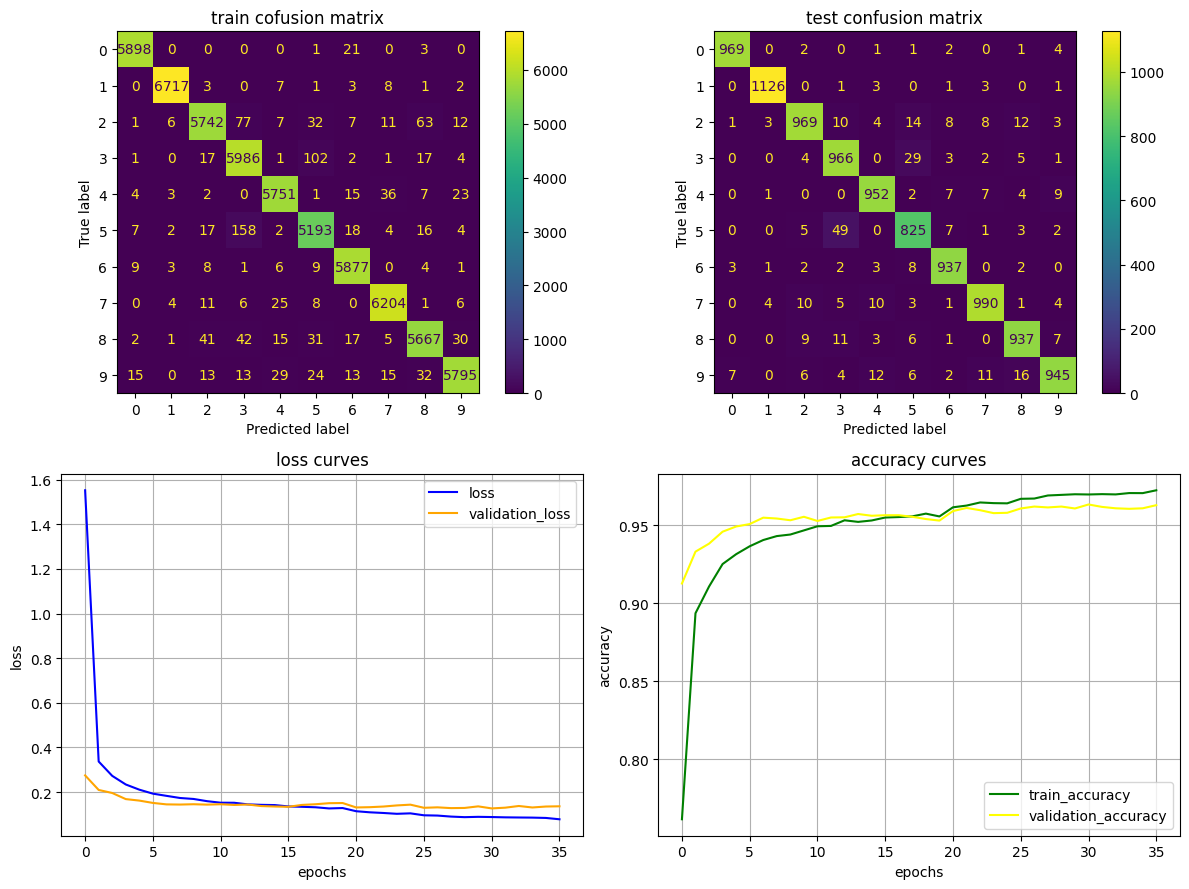

In [5]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

base_vgg16 = applications.VGG16(include_top=False, weights="imagenet", input_shape=(32, 32, 3))

model_vgg16 = crear_modelo(base_vgg16, "VGG16", applications.vgg16.preprocess_input)

met0, mod0, cm_tr0, cm_te0, pred_te0, h0 = entrenar_evaluar(model_vgg16, x_train, y_train, x_test, y_test)

metricas = pd.concat([metricas, pd.DataFrame([met0])], ignore_index=True)
display(metricas)
resumen(cm_tr0, cm_te0, h0)

Lo que más podemos notar a primera vista es el tiempo de entrenamiento y lo que le cuesta llegar al mínimo local. Tras casi 2 minutos de entrenamiento, obtenemos un 95.58% de accuracy (442 errores de 10000). Comparándolo con las prácticas anteriores donde superamos el 99%, este modelo se queda corto, además de durar el triple el entrenamiento.

### Experimento 1
Ahora usaremos la red DenseNet121. Esta formado por varios bloques de capas densas con capas convolucionales, batch normalization y función de activación ReLU. Cuenta con un total de 121 capas. Entre los bloques se reduce las dimensiones con convoluciones 1x1 y average pooling de 2x2.

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 70s 435ms/step - accuracy: 0.7871 - loss: 0.6472 - val_accuracy: 0.9292 - val_loss: 0.2390 - learning_rate: 0.0030
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9135 - loss: 0.2718 - val_accuracy: 0.9450 - val_loss: 0.1733 - learning_rate: 0.0030
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9316 - loss: 0.2144 - val_accuracy: 0.9506 - val_loss: 0.1543 - learning_rate: 0.0030
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9410 - loss: 0.1831 - val_accuracy: 0.9592 - val_loss: 0.1276 - learning_rate: 0.0030
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9447 - loss: 0.1679 - val_accuracy: 0.9601 - val_loss: 0.1228 - learning_rate: 0.0030
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9502 - loss: 0.1517 - val_accuracy: 0.9616 - val_loss: 0.1189 - learning_rate: 0.0030
Epoch 7/50
100/100 ━━━━━━━━━━

,modelo,tiempo_entrenamiento(s),train_accuracy,test_accuracy,errores_train,errores_test,precision,recall,f1_score,auc_roc
0,VGG16,210.00,0.9805,0.9616,1170/60000,384/10000,0.9610,0.9610,0.9609,0.9986
1,DenseNet121,167.77,0.9827,0.9670,1038/60000,330/10000,0.9668,0.9668,0.9666,0.9992


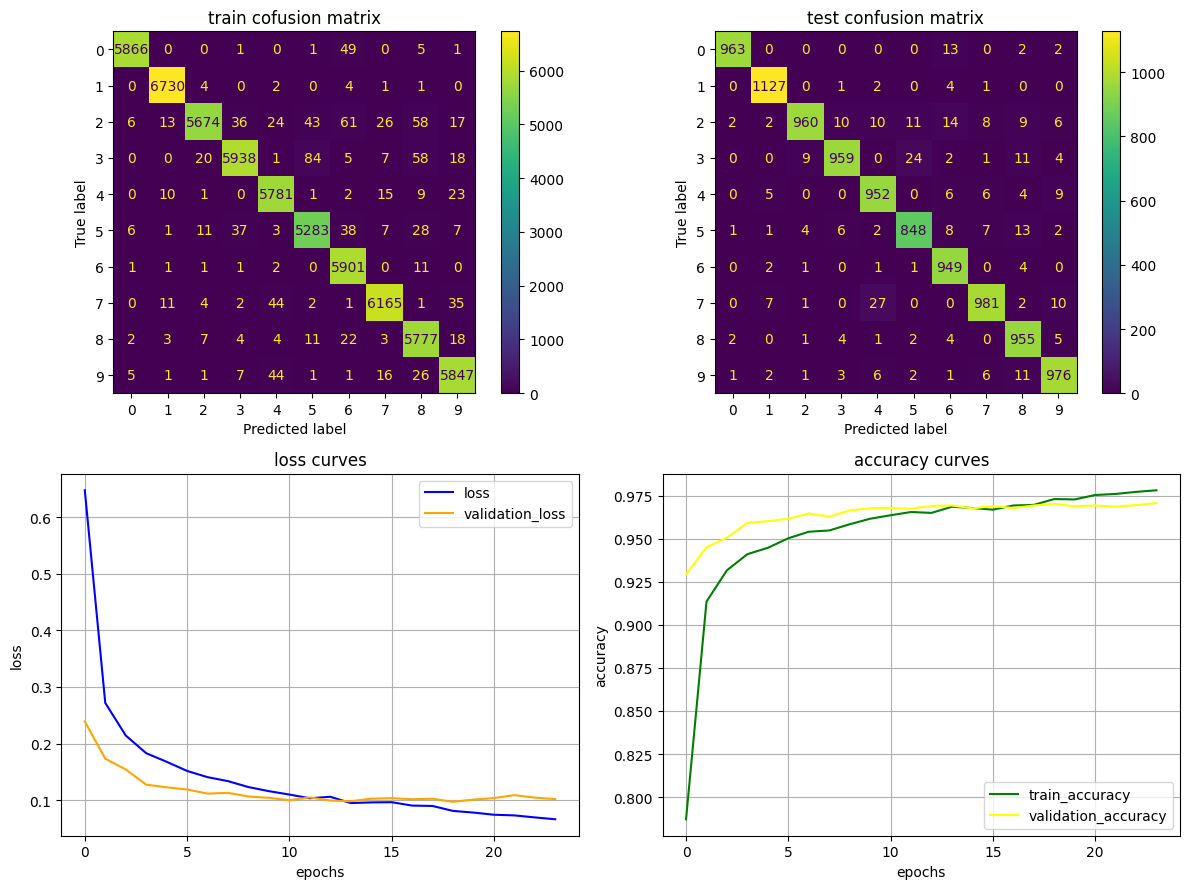

In [6]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

base_densenet121 = applications.DenseNet121(include_top=False, weights="imagenet", input_shape=(32, 32, 3))

model_densenet121 = crear_modelo(base_densenet121, "DenseNet121", applications.densenet.preprocess_input)

met1, mod1, cm_tr1, cm_te1, pred_te1, h1 = entrenar_evaluar(model_densenet121, x_train, y_train, x_test, y_test)

metricas = pd.concat([metricas, pd.DataFrame([met1])], ignore_index=True)
display(metricas)
resumen(cm_tr1, cm_te1, h1)

El entrenamiento ha durado casi 3 minutos, pero hemos mejorado el accuracy a un 96.77%, disminuyendo los errores a 323 de 10000. El aumento del tiempo del entrenamiento se debe a que la red es más profunda.

### Experimento 2
Ahora usaremos la red ResNet50V2. Está formada por 50 capas con un orden específico: batch normalization, ReLU, convolución. Este orden actúa como regularizador y mejora la generalización.

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 169ms/step - accuracy: 0.6772 - loss: 1.0001 - val_accuracy: 0.8112 - val_loss: 0.6162 - learning_rate: 0.0030
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7972 - loss: 0.6279 - val_accuracy: 0.8436 - val_loss: 0.5055 - learning_rate: 0.0030
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8242 - loss: 0.5411 - val_accuracy: 0.8566 - val_loss: 0.4570 - learning_rate: 0.0030
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.8389 - loss: 0.4953 - val_accuracy: 0.8682 - val_loss: 0.4231 - learning_rate: 0.0030
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8513 - loss: 0.4577 - val_accuracy: 0.8760 - val_loss: 0.3976 - learning_rate: 0.0030
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.8595 - loss: 0.4323 - val_accuracy: 0.8792 - val_loss: 0.3865 - learning_rate: 0.0030
Epoch 7/50
100/100 ━━━━━━━━━━

,modelo,tiempo_entrenamiento(s),train_accuracy,test_accuracy,errores_train,errores_test,precision,recall,f1_score,auc_roc
0,VGG16,210.00,0.9805,0.9616,1170/60000,384/10000,0.9610,0.9610,0.9609,0.9986
1,DenseNet121,167.77,0.9827,0.9670,1038/60000,330/10000,0.9668,0.9668,0.9666,0.9992
2,ResNet50V2,206.65,0.9371,0.9045,3777/60000,955/10000,0.9037,0.9031,0.9029,0.9929


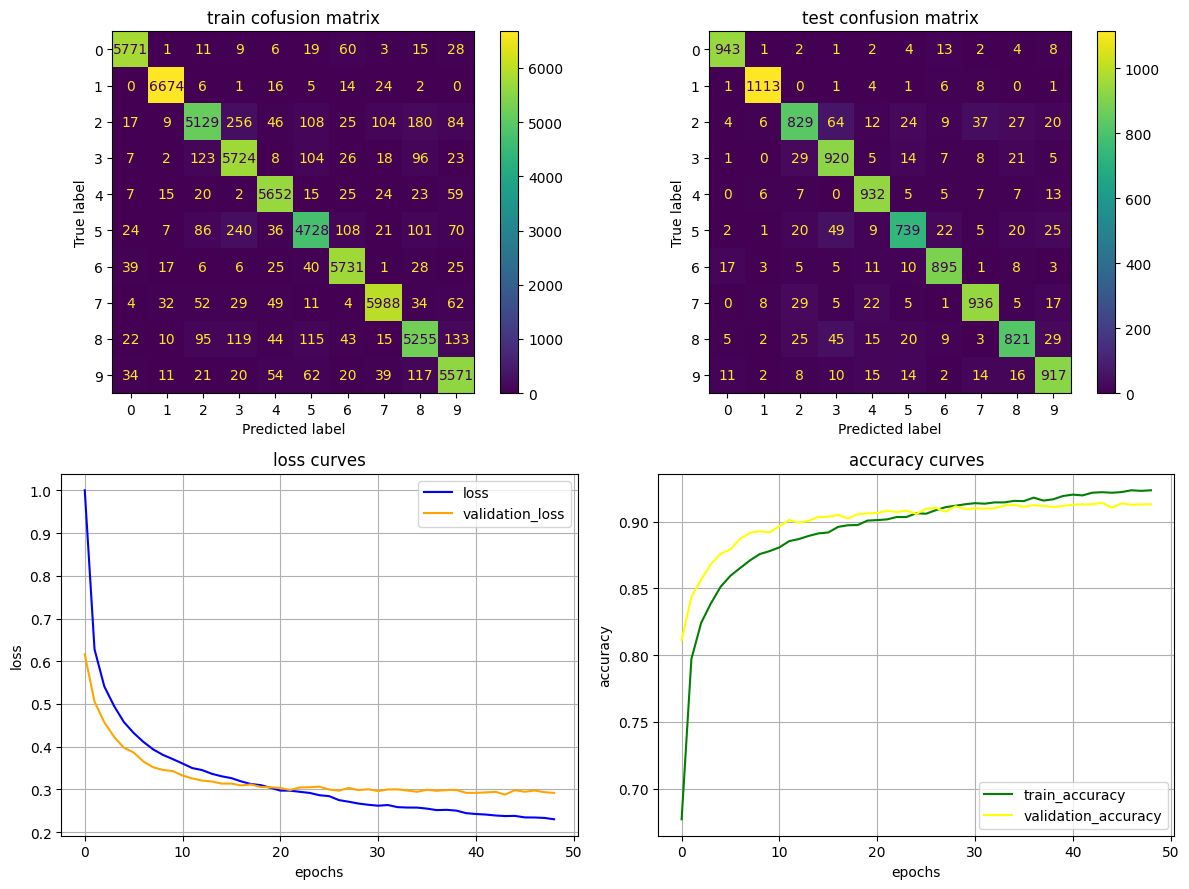

In [7]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

base_resnet50v2 = applications.ResNet50V2(include_top=False, weights="imagenet", input_shape=(32, 32, 3))

model_resnet50v2 = crear_modelo(base_resnet50v2, "ResNet50V2", applications.resnet_v2.preprocess_input)

met2, mod2, cm_tr2, cm_te2, pred_te2, h2 = entrenar_evaluar(model_resnet50v2, x_train, y_train, x_test, y_test)

metricas = pd.concat([metricas, pd.DataFrame([met2])], ignore_index=True)
display(metricas)
resumen(cm_tr2, cm_te2, h2)

De momento es el peor modelo en todos los aspectos, el que más ha durado y el que peor accuracy obtiene (90.53% y 947 errores de 10000). A pesar de tener ese orden de capas que se supone que mejora la generalización, parece ser que para este dataset no sirve de mucho a comparación con otros modelos.

### Experimento 3
Ahora usaremos la red EfficientNetV2B0. Está formada por 270 capas divididas en bloques, optimizados con ciertos algoritmos. Usa búsquedas automáticas de arquitectura para mejorar la velocidad de entrenamiento y la eficiencia.

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 52s 274ms/step - accuracy: 0.7729 - loss: 0.7002 - val_accuracy: 0.9199 - val_loss: 0.2577 - learning_rate: 0.0030
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8851 - loss: 0.3604 - val_accuracy: 0.9338 - val_loss: 0.2008 - learning_rate: 0.0030
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9043 - loss: 0.3005 - val_accuracy: 0.9426 - val_loss: 0.1716 - learning_rate: 0.0030
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9112 - loss: 0.2714 - val_accuracy: 0.9511 - val_loss: 0.1465 - learning_rate: 0.0030
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9185 - loss: 0.2527 - val_accuracy: 0.9522 - val_loss: 0.1449 - learning_rate: 0.0030
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9237 - loss: 0.2359 - val_accuracy: 0.9561 - val_loss: 0.1325 - learning_rate: 0.0030
Epoch 7/50
100/100 ━━━━━━━━━━

,modelo,tiempo_entrenamiento(s),train_accuracy,test_accuracy,errores_train,errores_test,precision,recall,f1_score,auc_roc
0,VGG16,210.00,0.9805,0.9616,1170/60000,384/10000,0.9610,0.9610,0.9609,0.9986
1,DenseNet121,167.77,0.9827,0.9670,1038/60000,330/10000,0.9668,0.9668,0.9666,0.9992
2,ResNet50V2,206.65,0.9371,0.9045,3777/60000,955/10000,0.9037,0.9031,0.9029,0.9929
3,EfficientNetV2B0,144.34,0.9791,0.9736,1253/60000,264/10000,0.9741,0.9727,0.9731,0.9995


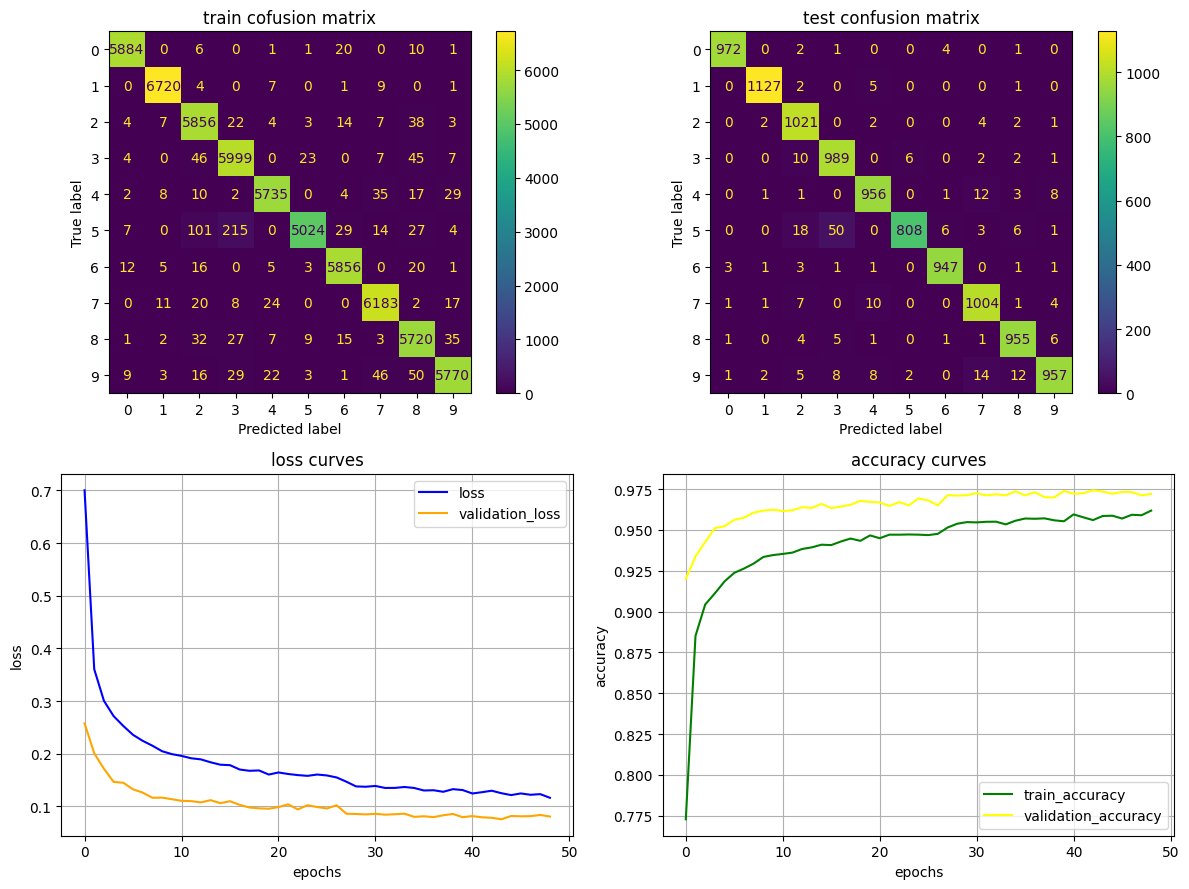

In [8]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

base_efficientnetv2b0 = applications.EfficientNetV2B0(include_top=False, weights="imagenet", input_shape=(32, 32, 3))

model_efficientnetv2b0 = crear_modelo(base_efficientnetv2b0, "EfficientNetV2B0", applications.efficientnet_v2.preprocess_input)

met3, mod3, cm_tr3, cm_te3, pred_te3, h3 = entrenar_evaluar(model_efficientnetv2b0, x_train, y_train, x_test, y_test)

metricas = pd.concat([metricas, pd.DataFrame([met3])], ignore_index=True)
display(metricas)
resumen(cm_tr3, cm_te3, h3)

De momento el mejor modelo hasta ahora. Obtenemos un 97.56% de accuracy y 244 fallos de 10000. A pesar de ver gráficamente que no ha llegado a converger al mínimo, el accuracy podría incluso llegar a mejorar más. Es lo que comentamos al principio, vamos a necesitar más tiempo y épocas para alcanzar el mínimo local.

### Experimento 4
Por último probaremos la red MobileNetV2. Está formada por 156 capas en total (con 53 capas convolucionales con pesos) estructuradas en bloques. Utiliza convoluciones en profundidad y funciones de activación ReLU6 para reducir el coste computacional, lo que la hace ideal para dispositivos móviles y de recursos limitados.

/tmp/ipykernel_1685/1316700850.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_mobilenetv2 = applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(32, 32, 3))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 130ms/step - accuracy: 0.5329 - loss: 1.4577 - val_accuracy: 0.6193 - val_loss: 1.1267 - learning_rate: 0.0030
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.6172 - loss: 1.1223 - val_accuracy: 0.6419 - val_loss: 1.0335 - learning_rate: 0.0030
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6333 - loss: 1.0584 - val_accuracy: 0.6527 - val_loss: 0.9901 - learning_rate: 0.0030
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6447 - loss: 1.0248 - val_accuracy: 0.6604 - val_loss: 0.9612 - learning_rate: 0.0030
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6519 - loss: 0.9995 - val_accuracy: 0.6673 - val_loss: 0.9436 - learning_rate: 0.0030
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6558 - loss: 0.9834 - val_accuracy: 0.6733 - val_loss: 0.9285 - learning_rate: 0.0030
Epoch 7/50
100/100 ━━━━━━━━━━━━

,modelo,tiempo_entrenamiento(s),train_accuracy,test_accuracy,errores_train,errores_test,precision,recall,f1_score,auc_roc
0,VGG16,210.00,0.9805,0.9616,1170/60000,384/10000,0.9610,0.9610,0.9609,0.9986
1,DenseNet121,167.77,0.9827,0.9670,1038/60000,330/10000,0.9668,0.9668,0.9666,0.9992
2,ResNet50V2,206.65,0.9371,0.9045,3777/60000,955/10000,0.9037,0.9031,0.9029,0.9929
3,EfficientNetV2B0,144.34,0.9791,0.9736,1253/60000,264/10000,0.9741,0.9727,0.9731,0.9995
4,MobileNetV2,93.87,0.7340,0.6954,15959/60000,3046/10000,0.6859,0.6893,0.6846,0.9493


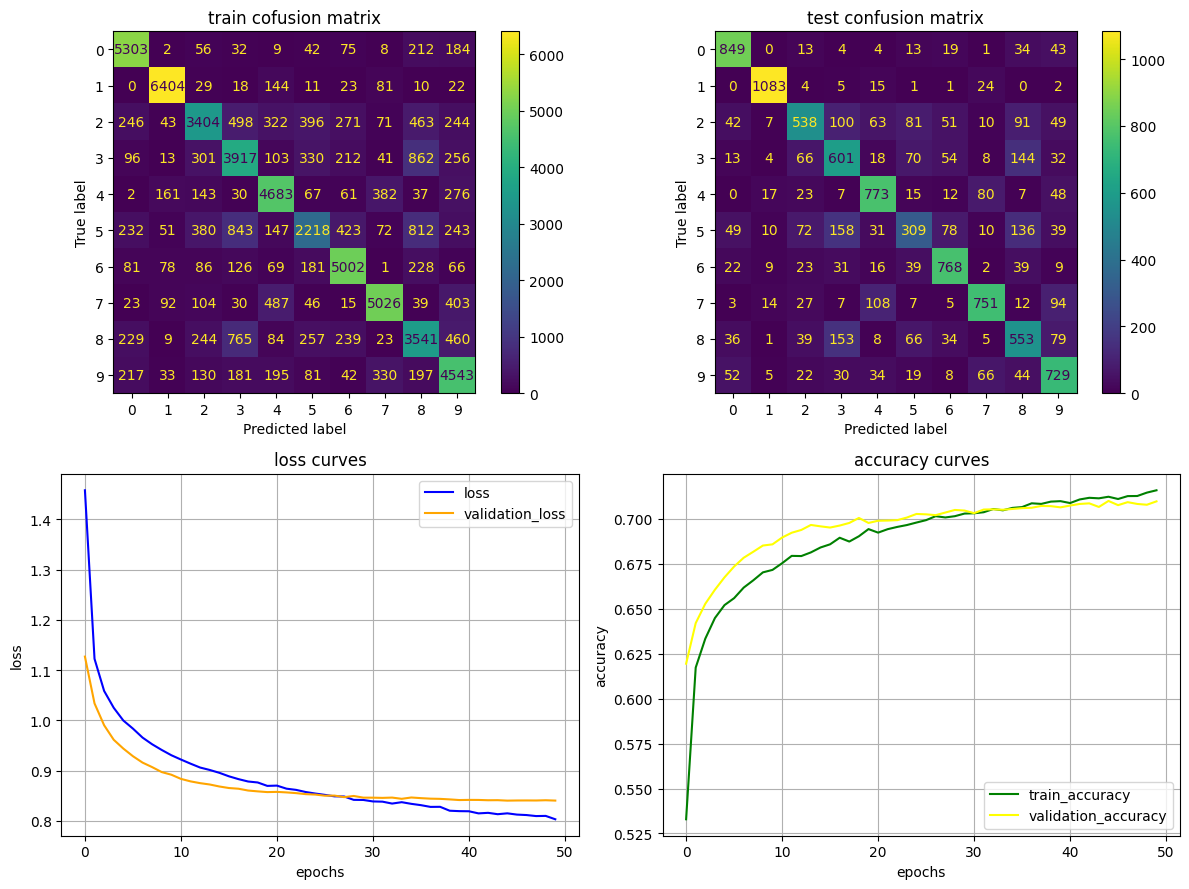

In [9]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

base_mobilenetv2 = applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(32, 32, 3))

model_mobilenetv2 = crear_modelo(base_mobilenetv2, "MobileNetV2", applications.mobilenet_v2.preprocess_input)

met4, mod4, cm_tr4, cm_te4, pred_te4, h4 = entrenar_evaluar(model_mobilenetv2, x_train, y_train, x_test, y_test)

metricas = pd.concat([metricas, pd.DataFrame([met4])], ignore_index=True)
display(metricas)
resumen(cm_tr4, cm_te4, h4)

El modelo más rápido y el peor a la vez. Llega a tan solo a un 69.54% de accuracy y 3046 fallos de 10000. Esto se debe a lo mejor al al meterle imágenes tan pequeñas, los mapas de características colapsan a dimensiones de 1x1 a mitad de la red, perdiendo la información de los trazos del dígito antes de llegar al final.

## Conclusión
Como hemos comprobado anteriormente, el mejor modelo hasta ahora es el EfficientNetV2B0. Lo almacenamos en disco:

In [ ]:
mod3.save("mejor_modelo_p4.keras")